# DDIM（2020）：非马尔可夫扩散与快速确定性采样

这个 notebook 使用八模态二维高斯混合分布，完整验证 *Denoising Diffusion Implicit Models* 的核心机制：

1. 不同前向过程可以共享相同的单时刻边缘分布 $q(x_t\mid x_0)$；
2. 改变跨时间噪声的相关性，不需要重新训练 DDPM 噪声预测网络；
3. $\eta=0$ 得到确定性 DDIM，$\eta>0$ 引入随机性；
4. DDIM 可以跳过大量时间步，用更少的网络调用（NFE）生成样本；
5. 用解析 Score 和八模态覆盖指标分别检验网络与采样器。

> 运行环境：`conda activate pytorch`。全部随机种子固定，可直接“全部运行”。

## 1. 八模态数据与 DDPM 噪声调度

八个均匀分量位于半径为 3 的圆上，每个分量协方差为 $0.25^2I$：

$$
p_{\mathrm{data}}(x)=\frac18\sum_{k=0}^{7}
\mathcal N\left(3(\cos\tfrac{k\pi}{4},\sin\tfrac{k\pi}{4}),0.25^2I\right).
$$

训练沿用 DDPM 的 1000 步线性调度。数组 `alpha_bars` 额外在位置 0 放入 $\bar\alpha_0=1$，因此代码时间 `t=1,...,1000` 与论文记号一致。

In [1]:
from pathlib import Path
import math
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

OUTPUT_DIR = Path("ddim_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

DIM = 2
NUM_MODES = 8
RADIUS = 3.0
DATA_STD = 0.25
T = 1_000
TRAIN_STEPS = 8_000
BATCH_SIZE = 1_024
N_SAMPLES = 3_000

angles = torch.arange(NUM_MODES, device=DEVICE)*2*math.pi/NUM_MODES
CENTERS = RADIUS*torch.stack([torch.cos(angles), torch.sin(angles)], dim=1)
WEIGHTS = torch.full((NUM_MODES,), 1/NUM_MODES, device=DEVICE)

betas = torch.linspace(1e-4, 0.02, T, device=DEVICE)
alpha_bars = torch.cat([torch.ones(1, device=DEVICE), torch.cumprod(1-betas, dim=0)])

print(f"PyTorch: {torch.__version__}")
print(f"Device: {DEVICE}")
print(f"alpha_bar_T: {alpha_bars[-1].item():.8f}")
print(f"Output directory: {OUTPUT_DIR.resolve()}")

PyTorch: 2.5.1
Device: cuda
alpha_bar_T: 0.00004036
Output directory: /home/zhangjinrui/my_program_code/Data_Processing/python/E2E/DLP/Diffuison/ddim_outputs


In [2]:
def sample_data(n):
    labels = torch.multinomial(WEIGHTS, n, replacement=True)
    return CENTERS[labels]+DATA_STD*torch.randn(n, DIM, device=DEVICE)


def q_sample(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)
    alpha_bar = alpha_bars[t, None]
    return torch.sqrt(alpha_bar)*x0+torch.sqrt(1-alpha_bar)*noise


with torch.no_grad():
    data_check = sample_data(20_000)
    assigned = torch.cdist(data_check, CENTERS).argmin(dim=1)
    empirical_weights = torch.bincount(assigned, minlength=NUM_MODES).float()/len(assigned)
print("Empirical mode weights:", empirical_weights.cpu().numpy().round(3))

Empirical mode weights: [0.122 0.124 0.126 0.127 0.128 0.127 0.123 0.123]


## 2. 前向扩散边缘分布

DDPM 与 DDIM 训练都使用相同的边缘扰动核：

$$
q(x_t\mid x_0)=\mathcal N(\sqrt{\bar\alpha_t}x_0,(1-\bar\alpha_t)I),
$$

即

$$
x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon.
$$

DDIM 改变的是不同时间随机变量之间的联合耦合，而不是这个单时刻边缘分布。

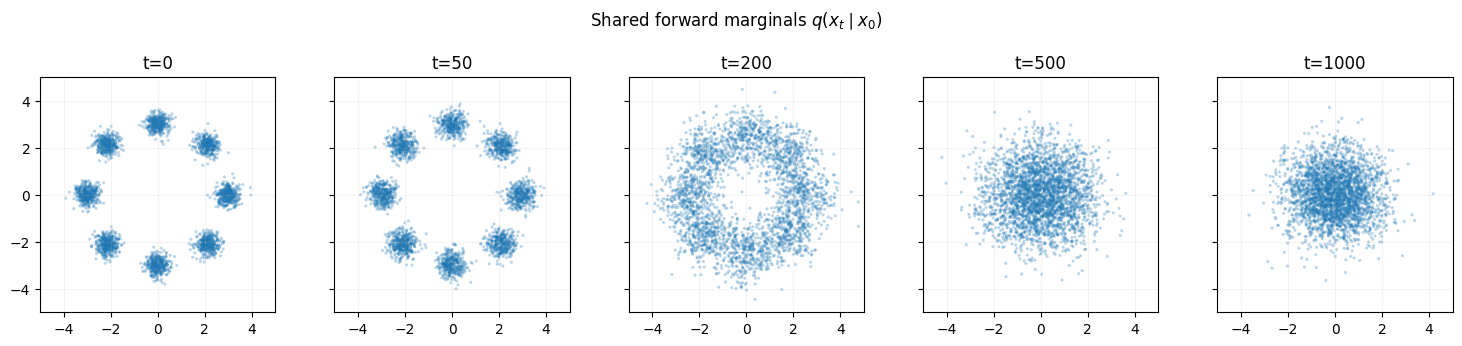

In [3]:
@torch.no_grad()
def plot_forward_diffusion():
    x0 = sample_data(N_SAMPLES)
    display_times = [0, 50, 200, 500, 1000]
    fig, axes = plt.subplots(1, 5, figsize=(15, 3.1), sharex=True, sharey=True)
    for ax, t_value in zip(axes, display_times):
        if t_value == 0:
            points = x0
        else:
            t = torch.full((N_SAMPLES,), t_value, dtype=torch.long, device=DEVICE)
            points = q_sample(x0, t)
        points = points.cpu().numpy()
        ax.scatter(points[:, 0], points[:, 1], s=5, alpha=0.3, edgecolors="none")
        ax.set_title(f"t={t_value}")
        ax.set_xlim(-5, 5)
        ax.set_ylim(-5, 5)
        ax.set_aspect("equal")
        ax.grid(alpha=0.15)
    fig.suptitle("Shared forward marginals $q(x_t\\mid x_0)$", y=1.04)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR/"01_forward_diffusion.png", dpi=160, bbox_inches="tight")
    plt.show()


plot_forward_diffusion()

## 3. $\eta$ 改变噪声耦合但不改变边缘方差

已知同一个真实 $x_0$ 和在时刻 $t$ 的噪声 $\epsilon_t$，DDIM 构造较早时刻 $s<t$：

$$
x_s=\sqrt{\bar\alpha_s}x_0
+\sqrt{1-\bar\alpha_s-\sigma_{t\to s}^2}\,\epsilon_t
+\sigma_{t\to s}z,
$$

$$
\sigma_{t\to s}^2=\eta^2
\frac{1-\bar\alpha_s}{1-\bar\alpha_t}
\left(1-\frac{\bar\alpha_t}{\bar\alpha_s}\right).
$$

无论 $\eta$ 如何变化，条件边缘方差始终是 $1-\bar\alpha_s$；变化的是 $x_s$ 与 $x_t$ 所用噪声之间的相关性。这个单元使用真实 $x_0,\epsilon_t$ 验证构造本身，不涉及神经网络采样。

  eta   target var   empirical var   theory corr  empirical corr
 0.00     0.804854        0.806020      1.000000        1.000000
 0.25     0.804854        0.802887      0.968450        0.968379
 0.50     0.804854        0.803499      0.866938        0.868261
 0.75     0.804854        0.802889      0.664123        0.663632
 1.00     0.804854        0.808385      0.079552        0.081247


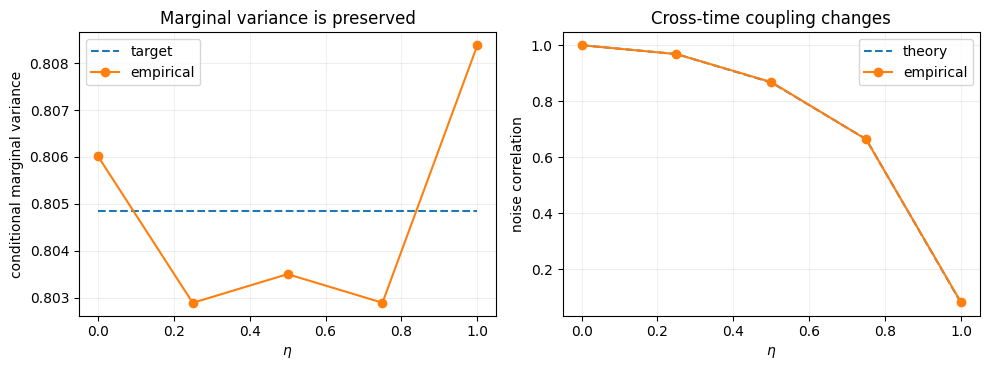

In [4]:
@torch.no_grad()
def coupling_experiment(t=800, s=400, n=50_000):
    alpha_t, alpha_s = alpha_bars[t], alpha_bars[s]
    x0 = torch.tensor([[2.0, -1.0]], device=DEVICE)
    epsilon_t = torch.randn(n, DIM, device=DEVICE)
    rows = []
    for eta in [0.0, 0.25, 0.5, 0.75, 1.0]:
        transition_var = eta**2*(1-alpha_s)/(1-alpha_t)*(1-alpha_t/alpha_s)
        shared_coeff = torch.sqrt((1-alpha_s-transition_var).clamp_min(0))
        x_s = (
            torch.sqrt(alpha_s)*x0
            +shared_coeff*epsilon_t
            +torch.sqrt(transition_var)*torch.randn_like(epsilon_t)
        )
        epsilon_s = (x_s-torch.sqrt(alpha_s)*x0)/torch.sqrt(1-alpha_s)
        empirical_var = (x_s-torch.sqrt(alpha_s)*x0).var(0).mean()
        empirical_corr = torch.corrcoef(torch.stack([epsilon_t[:, 0], epsilon_s[:, 0]]))[0, 1]
        theoretical_corr = shared_coeff/torch.sqrt(1-alpha_s)
        rows.append((eta, (1-alpha_s).item(), empirical_var.item(),
                     theoretical_corr.item(), empirical_corr.item()))
    return np.asarray(rows)


coupling_metrics = coupling_experiment()
print(f"{'eta':>5} {'target var':>12} {'empirical var':>15} {'theory corr':>13} {'empirical corr':>15}")
for row in coupling_metrics:
    print(f"{row[0]:5.2f} {row[1]:12.6f} {row[2]:15.6f} {row[3]:13.6f} {row[4]:15.6f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(coupling_metrics[:, 0], coupling_metrics[:, 1], "--", label="target")
axes[0].plot(coupling_metrics[:, 0], coupling_metrics[:, 2], "o-", label="empirical")
axes[0].set(xlabel=r"$\eta$", ylabel="conditional marginal variance", title="Marginal variance is preserved")
axes[1].plot(coupling_metrics[:, 0], coupling_metrics[:, 3], "--", label="theory")
axes[1].plot(coupling_metrics[:, 0], coupling_metrics[:, 4], "o-", label="empirical")
axes[1].set(xlabel=r"$\eta$", ylabel="noise correlation", title="Cross-time coupling changes")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"02_eta_coupling.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. 训练共享的 DDPM 噪声预测网络

DDIM 不需要新的训练目标。仍然均匀采样 $t$ 并最小化

$$
L_{\mathrm{simple}}=
\mathbb E\|\epsilon-\epsilon_\theta(x_t,t)\|^2.
$$

正弦时间编码让一个 MLP 同时处理 1000 个噪声等级。训练完成后，同一个网络会用于所有 $\eta$ 和不同 NFE 的采样。

In [5]:
class NoisePredictor(nn.Module):
    def __init__(self, hidden=128, time_dim=64):
        super().__init__()
        self.time_dim = time_dim
        self.net = nn.Sequential(
            nn.Linear(DIM+time_dim, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, DIM),
        )

    def time_embedding(self, t):
        half = self.time_dim//2
        frequencies = torch.exp(
            -math.log(10_000)*torch.arange(half, device=t.device)/max(half-1, 1)
        )
        angles = t.float()[:, None]*frequencies[None, :]
        return torch.cat([torch.sin(angles), torch.cos(angles)], dim=1)

    def forward(self, x, t):
        return self.net(torch.cat([x, self.time_embedding(t)], dim=1))


model = NoisePredictor().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

NoisePredictor(
  (net): Sequential(
    (0): Linear(in_features=66, out_features=128, bias=True)
    (1): SiLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): SiLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): SiLU()
    (6): Linear(in_features=128, out_features=2, bias=True)
  )
)
Trainable parameters: 41,858


In [6]:
losses = []
model.train()
training_started = time.perf_counter()
for step in range(1, TRAIN_STEPS+1):
    x0 = sample_data(BATCH_SIZE)
    t = torch.randint(1, T+1, (BATCH_SIZE,), device=DEVICE)
    noise = torch.randn_like(x0)
    xt = q_sample(x0, t, noise)
    loss = (model(xt, t)-noise).square().mean()

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

    if step == 1 or step % 800 == 0:
        print(f"step {step:4d}/{TRAIN_STEPS} | loss(200-step avg)={np.mean(losses[-200:]):.6f}")

print(f"Training finished in {time.perf_counter()-training_started:.1f} s")
torch.save(model.state_dict(), OUTPUT_DIR/"ddim_noise_predictor.pt")

step    1/8000 | loss(200-step avg)=1.055286


step  800/8000 | loss(200-step avg)=0.333387


step 1600/8000 | loss(200-step avg)=0.306701


step 2400/8000 | loss(200-step avg)=0.298966


step 3200/8000 | loss(200-step avg)=0.295881


...

step 4800/8000 | loss(200-step avg)=0.291848


step 5600/8000 | loss(200-step avg)=0.292750


step 6400/8000 | loss(200-step avg)=0.291464


step 7200/8000 | loss(200-step avg)=0.291319


step 8000/8000 | loss(200-step avg)=0.289176
Training finished in 23.8 s


## 5. 用解析边缘 Score 验收网络

扩散后的每个分量仍是高斯：均值为 $\sqrt{\bar\alpha_t}\mu_k$，方差为

$$
v_t=\bar\alpha_t\,0.25^2+(1-\bar\alpha_t).
$$

解析边缘 Score 可转换为最优噪声预测：

$$
\epsilon^*(x_t,t)=-\sqrt{1-\bar\alpha_t}\,\nabla_{x_t}\log p_t(x_t).
$$

这比单看训练 loss 更直接地检验网络是否学到了反向过程所需的信息。

     t    alpha_bar      noise MSE
    10     0.998105       0.014513
    50     0.971016       0.024450
   200     0.659039       0.012473
   500     0.078587       0.003152
   800     0.001532       0.002836
  1000     0.000040       0.002871


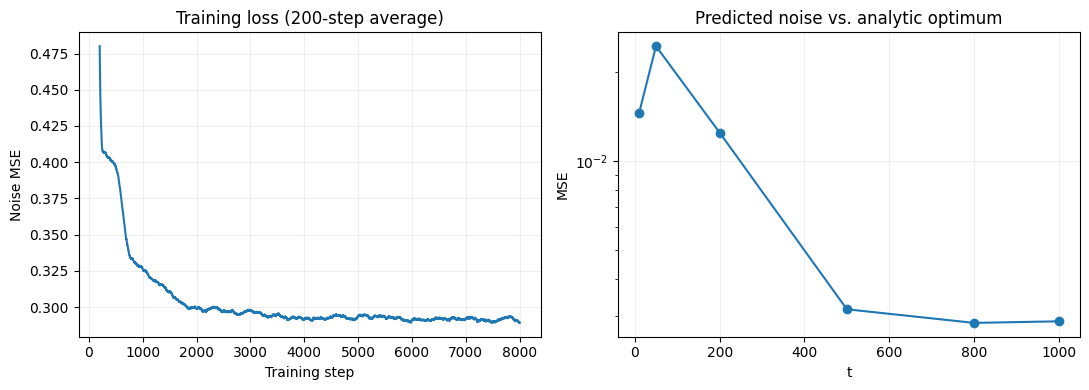

In [7]:
def exact_score(x, t):
    alpha_bar = alpha_bars[t, None]
    centers_t = torch.sqrt(alpha_bar)[:, None, :]*CENTERS[None, :, :]
    variance = (alpha_bar*DATA_STD**2+(1-alpha_bar))[:, None, :]
    delta = x[:, None, :]-centers_t
    logits = torch.log(WEIGHTS)[None, :]-delta.square().sum(-1)/(2*variance.squeeze(-1))
    responsibilities = torch.softmax(logits, dim=1)
    return (responsibilities[:, :, None]*(-delta/variance)).sum(dim=1)


def exact_noise(x, t):
    return -torch.sqrt(1-alpha_bars[t, None])*exact_score(x, t)


@torch.no_grad()
def evaluate_noise_predictor(n=10_000):
    model.eval()
    eval_times = [10, 50, 200, 500, 800, 1000]
    rows = []
    for t_value in eval_times:
        t = torch.full((n,), t_value, dtype=torch.long, device=DEVICE)
        xt = q_sample(sample_data(n), t)
        mse = (model(xt, t)-exact_noise(xt, t)).square().mean().item()
        rows.append((t_value, alpha_bars[t_value].item(), mse))
    return np.asarray(rows)


noise_metrics = evaluate_noise_predictor()
print(f"{'t':>6} {'alpha_bar':>12} {'noise MSE':>14}")
for t_value, alpha_bar, mse in noise_metrics:
    print(f"{int(t_value):6d} {alpha_bar:12.6f} {mse:14.6f}")

window = 200
loss_smooth = np.convolve(losses, np.ones(window)/window, mode="valid")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(np.arange(window, len(losses)+1), loss_smooth)
axes[0].set(xlabel="Training step", ylabel="Noise MSE", title=f"Training loss ({window}-step average)")
axes[1].semilogy(noise_metrics[:, 0], noise_metrics[:, 2], "o-")
axes[1].set(xlabel="t", ylabel="MSE", title="Predicted noise vs. analytic optimum")
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"03_training_and_noise_error.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. 广义 DDIM 跳步更新

从当前时间 $t$ 跳到较早时间 $s$：

$$
\hat x_0=\frac{x_t-\sqrt{1-\bar\alpha_t}\epsilon_\theta(x_t,t)}
{\sqrt{\bar\alpha_t}},
$$

$$
x_s=\sqrt{\bar\alpha_s}\hat x_0
+\sqrt{1-\bar\alpha_s-\sigma_{t\to s}^2}\epsilon_\theta(x_t,t)
+\sigma_{t\to s}z.
$$

- $\eta=0$：$\sigma_{t\to s}=0$，给定初始 $x_T$ 后轨迹完全确定；
- $0<\eta<1$：随机 DDIM；
- $\eta=1$：使用对应跳步后验方差的 DDPM 风格更新。

`NFE` 是噪声网络调用次数。使用少于 1000 个时间点，就是 DDIM 的加速来源。

In [8]:
@torch.no_grad()
def ddim_sample(noise_fn, initial_noise, nfe=50, eta=0.0, keep_stages=False):
    x = initial_noise.clone()
    times = np.linspace(T, 0, nfe+1).round().astype(int)
    snapshots = {0: x.cpu().numpy().copy()}

    for i, (t_value, s_value) in enumerate(zip(times[:-1], times[1:]), start=1):
        t = torch.full((len(x),), int(t_value), dtype=torch.long, device=DEVICE)
        epsilon = noise_fn(x, t)
        alpha_t, alpha_s = alpha_bars[t_value], alpha_bars[s_value]
        x0_hat = (x-torch.sqrt(1-alpha_t)*epsilon)/torch.sqrt(alpha_t)
        transition_var = eta**2*(1-alpha_s)/(1-alpha_t)*(1-alpha_t/alpha_s)
        x = (
            torch.sqrt(alpha_s)*x0_hat
            +torch.sqrt((1-alpha_s-transition_var).clamp_min(0))*epsilon
        )
        if s_value > 0 and eta > 0:
            x = x+torch.sqrt(transition_var)*torch.randn_like(x)
        if keep_stages and i in {nfe//4, nfe//2, 3*nfe//4, nfe}:
            snapshots[i] = x.cpu().numpy().copy()
    return x.cpu().numpy(), snapshots


initial_noise = torch.randn(N_SAMPLES, DIM, device=DEVICE)
sampling_started = time.perf_counter()
eta_samples = {}
for eta in [0.0, 0.5, 1.0]:
    eta_samples[eta], _ = ddim_sample(model, initial_noise, nfe=50, eta=eta)

deterministic_repeat, _ = ddim_sample(model, initial_noise, nfe=50, eta=0.0)
max_repeat_difference = np.max(np.abs(eta_samples[0.0]-deterministic_repeat))
oracle_sample, _ = ddim_sample(exact_noise, initial_noise, nfe=50, eta=0.0)
print(f"Sampling finished in {time.perf_counter()-sampling_started:.1f} s")
print(f"Repeated deterministic sampling max difference: {max_repeat_difference:.10f}")

Sampling finished in 0.3 s
Repeated deterministic sampling max difference: 0.0000000000


## 7. 比较 $\eta$ 与解析 Oracle

三种学习采样共享同一个初始噪声。Oracle DDIM 使用解析边缘 Score 对应的最优噪声预测，因此它能隔离有限 NFE 的离散误差。

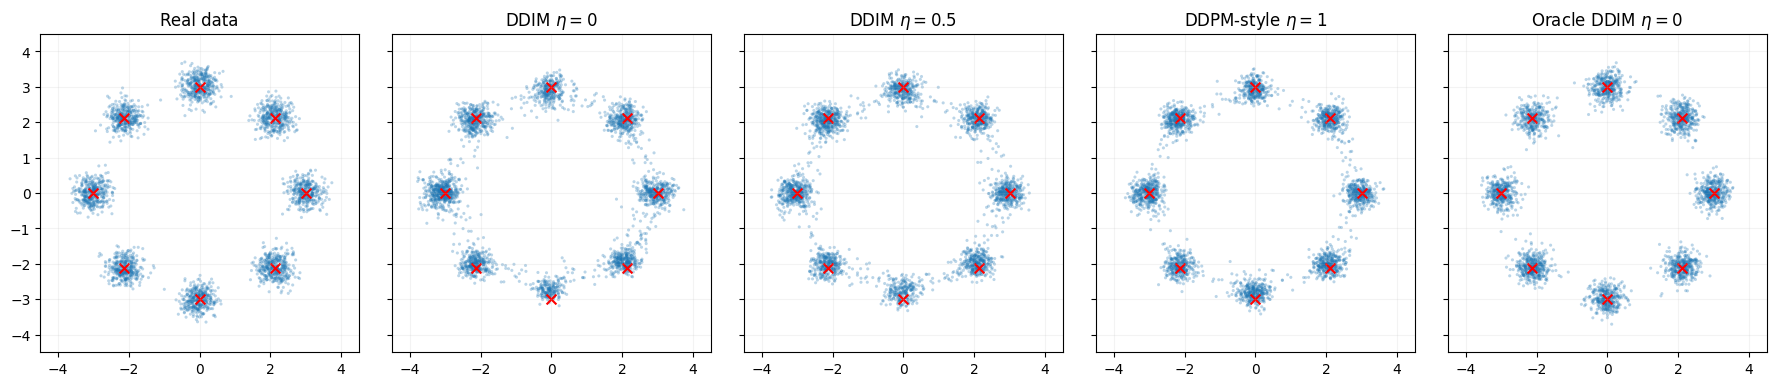

sampler                 modes    max |w-1/8|   center err   avg std
Real data                   8         0.0087       0.0179    0.2513
DDIM $\eta=0$               8         0.0507       0.1411    0.2612
DDIM $\eta=0.5$             8         0.0350       0.1102    0.2587
DDPM-style $\eta=1$         8         0.0183       0.0896    0.2383
Oracle DDIM $\eta=0$        8         0.0153       0.0258    0.2403


In [9]:
def scatter(ax, points, title):
    ax.scatter(points[:, 0], points[:, 1], s=5, alpha=0.3, edgecolors="none")
    ax.scatter(CENTERS[:, 0].cpu(), CENTERS[:, 1].cpu(), c="red", marker="x", s=50)
    ax.set(title=title, xlim=(-4.5, 4.5), ylim=(-4.5, 4.5))
    ax.set_aspect("equal")
    ax.grid(alpha=0.15)


with torch.no_grad():
    real = sample_data(N_SAMPLES).cpu().numpy()

comparison = [
    ("Real data", real),
    (r"DDIM $\eta=0$", eta_samples[0.0]),
    (r"DDIM $\eta=0.5$", eta_samples[0.5]),
    (r"DDPM-style $\eta=1$", eta_samples[1.0]),
    (r"Oracle DDIM $\eta=0$", oracle_sample),
]
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6), sharex=True, sharey=True)
for ax, (title, points) in zip(axes, comparison):
    scatter(ax, points, title)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"04_eta_comparison.png", dpi=160, bbox_inches="tight")
plt.show()


def mode_metrics(points):
    points_t = torch.as_tensor(points, dtype=torch.float32, device=DEVICE)
    labels = torch.cdist(points_t, CENTERS).argmin(dim=1)
    counts = torch.bincount(labels, minlength=NUM_MODES).float()
    weights = counts/len(points_t)
    means = torch.stack([points_t[labels == i].mean(0) for i in range(NUM_MODES)])
    stds = torch.stack([points_t[labels == i].std(0) for i in range(NUM_MODES)])
    center_error = torch.linalg.vector_norm(means-CENTERS, dim=1).mean()
    max_weight_error = (weights-1/NUM_MODES).abs().max()
    modes_covered = int((weights > 0.02).sum())
    return modes_covered, max_weight_error.item(), center_error.item(), stds.mean().item()


print(f"{'sampler':<22} {'modes':>6} {'max |w-1/8|':>14} {'center err':>12} {'avg std':>9}")
for title, points in comparison:
    covered, weight_error, center_error, avg_std = mode_metrics(points)
    print(f"{title:<22} {covered:6d} {weight_error:14.4f} {center_error:12.4f} {avg_std:9.4f}")

## 8. 少步采样：NFE 与质量的关系

使用同一个初始噪声和确定性 $\eta=0$，比较 10、20、50、100 次网络调用。NFE 越小速度越快，但 $\hat x_0$ 的误差会在更大的跳步中累积。二维八模态任务可用模态覆盖、中心误差和分量标准差直接衡量这种折衷。

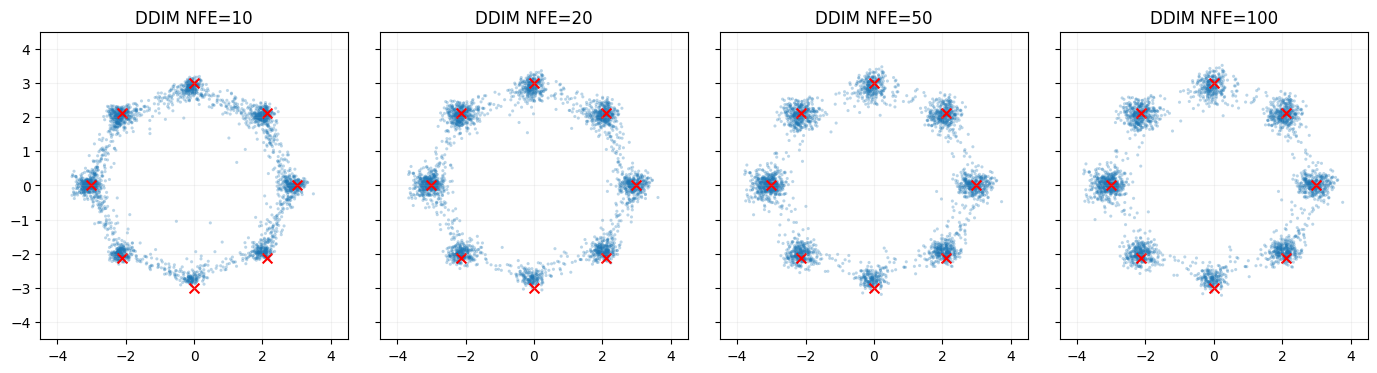

   NFE  modes    max |w-1/8|   center err   avg std
    10      8         0.0693       0.2128    0.2835
    20      8         0.0583       0.1687    0.2620
    50      8         0.0507       0.1411    0.2612
   100      8         0.0500       0.1346    0.2629


In [10]:
nfe_values = [10, 20, 50, 100]
nfe_samples = {}
for nfe in nfe_values:
    nfe_samples[nfe], _ = ddim_sample(model, initial_noise, nfe=nfe, eta=0.0)

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), sharex=True, sharey=True)
for ax, nfe in zip(axes, nfe_values):
    scatter(ax, nfe_samples[nfe], f"DDIM NFE={nfe}")
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"05_nfe_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

print(f"{'NFE':>6} {'modes':>6} {'max |w-1/8|':>14} {'center err':>12} {'avg std':>9}")
for nfe in nfe_values:
    covered, weight_error, center_error, avg_std = mode_metrics(nfe_samples[nfe])
    print(f"{nfe:6d} {covered:6d} {weight_error:14.4f} {center_error:12.4f} {avg_std:9.4f}")

## 9. 确定性 DDIM 轨迹

对固定 $x_T$，$\eta=0$ 不再注入随机噪声，因此每个中间状态都是初始噪声和网络参数的确定函数。下面展示 50 NFE 的群体轨迹；从标准高斯开始，样本先沿圆周展开，再分裂并收缩到八个模态。

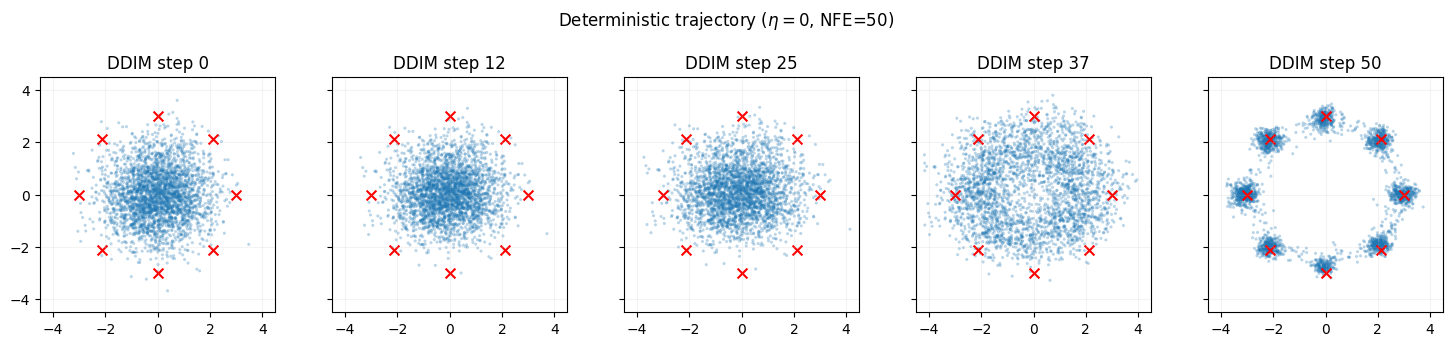

In [11]:
trajectory_sample, trajectory = ddim_sample(
    model, initial_noise, nfe=50, eta=0.0, keep_stages=True
)
stage_ids = [0, 50//4, 50//2, 3*50//4, 50]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.1), sharex=True, sharey=True)
for ax, stage in zip(axes, stage_ids):
    scatter(ax, trajectory[stage], f"DDIM step {stage}")
fig.suptitle(r"Deterministic trajectory ($\eta=0$, NFE=50)", y=1.04)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"06_deterministic_trajectory.png", dpi=160, bbox_inches="tight")
plt.show()

## 10. 代码与论文公式对应关系

| Notebook 对象 | 数学对象 | 作用 |
|---|---|---|
| `alpha_bars` | $\bar\alpha_t$ | 共享的单时刻前向边缘 |
| `q_sample()` | $q(x_t\mid x_0)$ | DDPM/DDIM 共用的训练扰动 |
| `coupling_experiment()` | $q_\sigma(x_{1:T}\mid x_0)$ | 验证边缘不变、耦合改变 |
| `NoisePredictor` | $\epsilon_\theta(x_t,t)$ | 共用的 DDPM 噪声网络 |
| `transition_var` | $\sigma_{t\to s}^2$ | 由 $\eta$ 控制的采样随机性 |
| `x0_hat` | $f_\theta^{(t)}(x_t)$ | 从噪声预测重建干净样本 |
| `ddim_sample()` | 广义 DDIM 更新 | 支持跳步与不同 $\eta$ |
| `exact_noise()` | 解析最优噪声预测 | 隔离网络误差与离散误差 |

### 最重要的实验结论

- 相同的 $q(x_t\mid x_0)$ 足以复用同一个训练目标，完整前向联合过程不必唯一。
- $\eta$ 改变轨迹随机性和跨时间相关性，但构造中的单时刻条件边缘方差保持不变。
- $\eta=0$ 对固定 $x_T$ 完全确定；重复执行的最大差异应为 0。
- 少步 DDIM 的速度来自跳过时间点；生成质量取决于网络精度与离散步长。